# ПЗ3. Задача и базлайн

БИВТ-23-АЭ-1, группа № 3 · Колосова, Ахмадеева, Мочалов · 30.10.2026
Данные: Telco Customer Churn, 7043 × 21 (паспорт ПЗ2).

## 1. Постановка

- **What:** вероятность ухода, Churn = Yes, на одном пересчёте базы.
- **Why:** ушедшие — 26,5% клиентов и 30,5% месячной выручки.
- **Who:** менеджер по удержанию.
- **How measure:** PR-AUC; вспомогательные — precision и recall по «ушёл».
- **When good:** при бюджете 20% базы recall ≥ 45% и precision ≥ 60%.

Тип — бинарная классификация. Accuracy не годится: «все остаются» даёт 73,5%.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

BUDGET, SEED = 0.20, 42
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

pct = lambda x, d=1: f"{x:.{d}f}".replace(".", ",") + "%"
num = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")

DATA = next((p for p in (Path("../data/telco_churn.csv"), Path("data/telco_churn.csv"),
                         Path("telco_churn.csv")) if p.exists()), None)
if DATA is None:
    raise SystemExit("положите telco_churn.csv в project/data")

df = pd.read_csv(DATA, keep_default_na=False)
print(DATA, df.shape)

../data/telco_churn.csv (7043, 21)


In [2]:
blank = df.apply(lambda s: s.astype(str).str.strip().eq("").sum())
print("пропуски:", blank[blank > 0].to_dict())
print("дубликаты:", int(df.duplicated().sum()),
      "| без ключа:", int(df.drop(columns=["customerID"]).duplicated().sum()))
print("отток:", pct((df["Churn"] == "Yes").mean() * 100, 2))

пропуски: {'TotalCharges': 11}
дубликаты: 0 | без ключа: 22
отток: 26,54%


In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", pd.NA), errors="coerce")
df["новый_клиент"] = (df["tenure"] == 0).astype(int)
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["ушёл"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID", "Churn"])
print(df.shape, "| отток", pct(df["ушёл"].mean() * 100, 2))

(7043, 21) | отток 26,54%


## 2. Сплит

Дат в данных нет, один клиент — одна строка: стратифицированный 80/20 до обработки.

In [4]:
train, val = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["ушёл"])
print(f"обучение {len(train)} | валидация {len(val)} | отток {pct(val['ушёл'].mean() * 100, 2)}")
y_val = val["ушёл"]

обучение 5634 | валидация 1409 | отток 26,54%


## 3. Базлайн и модель

Одна метрика, одна валидация. Базлайн — правило из паспорта ПЗ2.

In [5]:
def report(name, y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {"решение": name,
           "precision": round(precision_score(y_true, y_pred, zero_division=0), 3),
           "recall": round(recall_score(y_true, y_pred, zero_division=0), 3),
           "f1": round(f1_score(y_true, y_pred, zero_division=0), 3),
           "отмечено": int(y_pred.sum()),
           "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}
    if y_score is not None:
        out["ROC_AUC"] = round(roc_auc_score(y_true, y_score), 3)
        out["PR_AUC"] = round(average_precision_score(y_true, y_score), 3)
    return out


results = []

In [6]:
freq_pred = np.zeros(len(val), dtype=int)
results.append(report("Базлайн: «все остаются»", y_val, freq_pred))
print("accuracy «все остаются»:", pct((freq_pred == y_val).mean() * 100, 1))

accuracy «все остаются»: 73,5%


In [7]:
rule_pred = (val["Contract"] == "Month-to-month").astype(int).to_numpy()
results.append(report("Базлайн: правило «помесячный контракт»", y_val, rule_pred))
print(f"правило помечает {rule_pred.sum()} из {len(val)} ({pct(rule_pred.mean() * 100, 1)})")

правило помечает 773 из 1409 (54,9%)


In [8]:
NUM = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "новый_клиент"]
CAT = [c for c in df.columns if c not in NUM + ["ушёл"]]

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])
model = Pipeline([("prep", prep),
                  ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])
model.fit(train[NUM + CAT], train["ушёл"])
proba = model.predict_proba(val[NUM + CAT])[:, 1]

results.append(report("Модель, порог 0,5", y_val, (proba >= 0.5).astype(int), proba))
pd.DataFrame(results).set_index("решение")

,precision,recall,f1,отмечено,TP,FP,FN,TN,ROC_AUC,PR_AUC
решение,,,,,,,,,,
Базлайн: «все остаются»,0.000,0.000,0.000,0,0,0,374,1035,NaN,NaN
Базлайн: правило «помесячный контракт»,0.426,0.880,0.574,773,329,444,45,591,NaN,NaN
"Модель, порог 0,5",0.658,0.561,0.606,319,210,109,164,926,0.842,0.634


In [9]:
rows = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (proba >= t).astype(int)
    if pred.sum():
        rows.append({"порог": round(float(t), 2), "отмечено": int(pred.sum()),
                     "precision": round(precision_score(y_val, pred, zero_division=0), 3),
                     "recall": round(recall_score(y_val, pred, zero_division=0), 3)})
thr_df = pd.DataFrame(rows)

k = int(np.floor(BUDGET * len(val)))
thr_budget = float(np.sort(proba)[::-1][k - 1])
print(f"бюджет {k} клиентов, порог {num(thr_budget)}")

бюджет 281 клиентов, порог 0,53


In [10]:
pred_budget = (proba >= thr_budget).astype(int)
results.append(report(f"Модель, порог {num(thr_budget)} (бюджет 20%)",
                      y_val, pred_budget, proba))
final = pd.DataFrame(results).set_index("решение")
final

,precision,recall,f1,отмечено,TP,FP,FN,TN,ROC_AUC,PR_AUC
решение,,,,,,,,,,
Базлайн: «все остаются»,0.000,0.000,0.000,0,0,0,374,1035,NaN,NaN
Базлайн: правило «помесячный контракт»,0.426,0.880,0.574,773,329,444,45,591,NaN,NaN
"Модель, порог 0,5",0.658,0.561,0.606,319,210,109,164,926,0.842,0.634
"Модель, порог 0,53 (бюджет 20%)",0.662,0.497,0.568,281,186,95,188,940,0.842,0.634


### Сравнение при равном бюджете

Правило не ранжирует: чтобы влезть в бюджет, из помеченных берут случайную часть.

In [11]:
y = val["ушёл"].to_numpy()
rule_tp = int(((rule_pred == 1) & (y == 1)).sum())
rule_precision = rule_tp / rule_pred.sum()
scale = k / rule_pred.sum()

model_tp = int(((pred_budget == 1) & (y == 1)).sum())
model_precision = model_tp / pred_budget.sum()
model_recall = model_tp / y.sum()

print(f"правило: ~{rule_tp * scale:.0f} попаданий, precision {pct(rule_precision * 100, 1)}")
print(f"модель:  {model_tp} попаданий, precision {pct(model_precision * 100, 1)}")

правило: ~120 попаданий, precision 42,6%
модель:  186 попаданий, precision 66,2%


## 4. Вердикт

In [12]:
print("порог достигнут:", "да" if model_recall >= 0.45 and model_precision >= 0.60 else "нет")
print(f"recall {pct(model_recall * 100, 1)} при плане 45%, precision {pct(model_precision * 100, 1)} при плане 60%")
print(f"PR-AUC {num(average_precision_score(y_val, proba), 3)}, ROC-AUC {num(roc_auc_score(y_val, proba), 3)}")

порог достигнут: да
recall 49,7% при плане 45%, precision 66,2% при плане 60%
PR-AUC 0,634, ROC-AUC 0,842


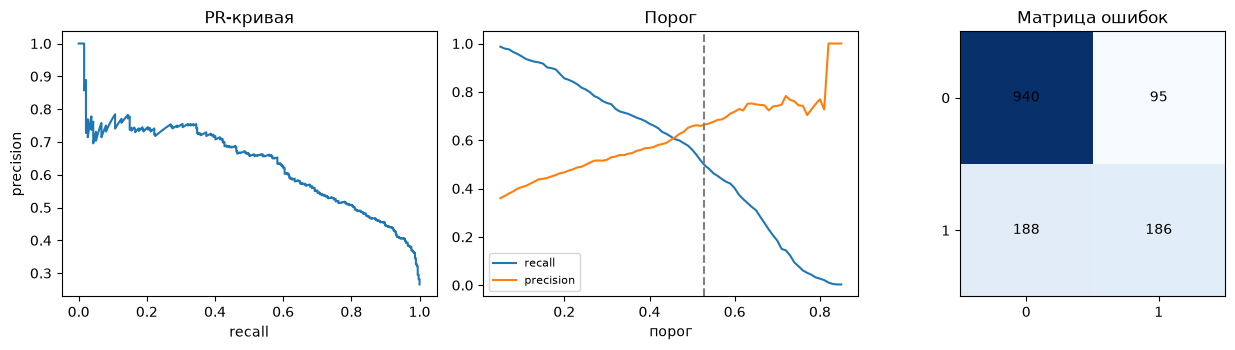

In [13]:
prec, rec, _ = precision_recall_curve(y_val, proba)
cm = confusion_matrix(y_val, pred_budget, labels=[0, 1])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(rec, prec)
ax[0].set(xlabel="recall", ylabel="precision", title="PR-кривая")
ax[1].plot(thr_df["порог"], thr_df["recall"], label="recall")
ax[1].plot(thr_df["порог"], thr_df["precision"], label="precision")
ax[1].axvline(thr_budget, ls="--", c="gray")
ax[1].set(xlabel="порог", title="Порог"); ax[1].legend(fontsize=8)
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha="center", va="center")
ax[2].set(title="Матрица ошибок", xticks=[0, 1], yticks=[0, 1])
plt.tight_layout()
plt.savefig(FIG / "pz3.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Журнал

In [14]:
pd.DataFrame([
    ["1", "Базлайн «все остаются»", "accuracy 73,5%, recall 0", "планка бессмысленности"],
    ["2", "Правило «помесячный контракт»", "precision 0,426, recall 0,880", "не влезает в бюджет"],
    ["3", "Модель, порог 0,5", "precision 0,658, recall 0,561", "лучше правила, но 22,6% базы"],
    ["4", "Модель, бюджет 20%", "precision 0,662, recall 0,497", "выбранный вариант"],
], columns=["№", "что пробовали", "метрики", "вывод"]).set_index("№")

,что пробовали,метрики,вывод
№,,,
1,Базлайн «все остаются»,"accuracy 73,5%, recall 0",планка бессмысленности
2,Правило «помесячный контракт»,"precision 0,426, recall 0,880",не влезает в бюджет
3,"Модель, порог 0,5","precision 0,658, recall 0,561","лучше правила, но 22,6% базы"
4,"Модель, бюджет 20%","precision 0,662, recall 0,497",выбранный вариант
